# Human Activity States Using a NumPy Hidden Markov Model

**Author: Mahamat bakhit**

[GitHub repository](https://github.com/Mahamatbt/human-activity-hmm) · [Four activity videos](https://mahamatbt.github.io/human-activity-hmm/)

Remaining rubric requirements are documented in `rubric_status.md`.

**Final v2 evaluation added, 28 October 2026. Historical mixed-run references remain approximate.**

Eleven real recordings are available: four new single-activity test files plus the original seven. The original seven include: four isolated training files, one mixed training
run, one mixed validation run and one later mixed test run. All are from one participant
and iPhone on the same afternoon. No synthetic data are used in this experiment.

The participant confirmed the activity orders but did not measure change times.
Mixed-run annotations therefore use **approximate, signal-assisted boundaries**.
The test order jumping -> walking -> still -> standing was explicitly confirmed twice.
We retain that order despite a quiet interval at about 16-23 s followed by movement
at 24-39 s. Do not relabel the test to fit predictions. These references are not
independently time-verified ground truth, and all resulting metrics are provisional.

Annotation hashes were fixed before new model selection. A predefined 2 s guard
excludes boundary neighbourhoods from mixed-run emission fitting and a separate
stable-core check. It is not a measured confidence bound or a remedy for incorrect
reference order/times. See `analysis_status.md` and `data/annotation_provenance.json`.


**V2 update:** a development-only comparison now follows the original baseline below.
It selected a four-feature log-scaled HMM at 19/21 = 90.48% validation accuracy.
The frozen v2 model was then evaluated on four new single-activity recordings:
27/30 = 90.00% test accuracy. The original 45.83% result remains historical v1
evidence against approximate mixed-run labels. See results/fresh_test_v2/summary.json.


## 1. Optional Colab preparation

For local Jupyter, skip the next cell. In Colab, upload a zip named
`human_activity_hmm.zip` containing the entire folder at its top level, then run it.
Make a fresh zip after adding your real recordings. Uploading only this notebook
will not supply its implementation or data. Colab files are temporary.


In [1]:
# OPTIONAL: uncomment these lines in Google Colab after uploading the project zip.
# %pip -q install numpy pandas scipy matplotlib
# import zipfile
# with zipfile.ZipFile('/content/human_activity_hmm.zip') as archive:
#     archive.extractall('/content')


In [2]:
from pathlib import Path
import sys, json, platform, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Code

candidates = [Path.cwd(), Path.cwd() / 'human_activity_hmm', Path('/content/human_activity_hmm')]
ROOT = next((p for p in candidates if (p / 'activity_hmm.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open Jupyter in the project folder, or upload/extract the entire project zip in Colab.')
sys.path.insert(0, str(ROOT))
from activity_hmm import (
    STATES, FEATURE_NAMES, GaussianHMM, build_dataset, fit_scaler, apply_scaler, evaluate,
)
( ROOT / 'results' ).mkdir(exist_ok=True)

TARGET_HZ = 50    # Proposed common rate. Verify pilot measurements first.
WINDOW_S = 2     # Non-overlapping windows; at 50 Hz, 100 rows per observation.
RUN_FINAL_TEST = True  # Executed after validation selection below; approximate references only.
print('Project:', ROOT)
print('Python:', platform.python_version(), '| NumPy:', np.__version__, '| pandas:', pd.__version__)


Project: /Users/ndtltd/Documents/ChatGPT/formative group/human_activity_hmm
Python: 3.13.0 | NumPy: 2.4.3 | pandas: 3.0.1


## 2. Collection manifest, rate audit and preprocessing

Only rows marked `recorded` in `data/recordings.csv` are loaded. Keep the raw exports
unchanged. The loader expects calibrated, gravity-free iOS acceleration (m/s²) and
gyroscope (rad/s), each with `seconds_elapsed,x,y,z` on the same recording clock.

We measure timestamp spacing, report duplicates/invalid rows, reject gaps >0.2 s,
regularize minor jitter, low-pass filter (4th-order Butterworth at 0.4 times the lower
of native and target rate), and align sensors to the same grid. Filtering uses future
samples; this is an offline experiment. A native rate materially below the target
raises an error instead of silently suggesting extra information from upsampling.

Mixed recording annotations must cover the full retained interval. A window is
labelled by the state at its midpoint; its purity is the fraction of time in that state.
Independent recordings remain separate sequences. There is no random window split.


In [3]:
manifest = pd.read_csv(ROOT / 'data/recordings.csv', keep_default_na=False)
print('Planned or completed recordings:', len(manifest))
print('Recordings ready:', int(manifest.status.eq('recorded').sum()))
sequences, sampling_audit = build_dataset(ROOT, target_hz=TARGET_HZ, window_s=WINDOW_S)
if sequences:
    display(sampling_audit)
    sampling_audit.to_csv(ROOT / 'results/sampling_audit.csv', index=False)
    summary = pd.DataFrame([
        dict(recording_id=s['recording_id'], session=s['session_id'], split=s['split'],
             activity=s['activity'], windows=len(s['y']),
             pure_windows=int((s['purity'] >= 1 - 1e-6).sum()),
             stable_core_windows=int(s['stable'].sum()), annotation_quality=s['annotation_quality']) for s in sequences
    ])
    display(summary)
    summary.to_csv(ROOT / 'results/recording_summary.csv', index=False)
else:
    print('Next: inspect a pilot export, add its CSVs, verify the trim times, and mark its manifest row recorded.')


Planned or completed recordings: 7
Recordings ready: 7


,sensor_file,input_rows,valid_unique_rows,invalid_rows_removed,duplicate_timestamps_removed,median_rate_hz,average_rate_hz,largest_gap_s,interval_iqr_s,recording_id,sensor,requested_rate_hz,resampled_rate_hz,trim_start_s,trim_end_s
0,/Users/ndtltd/Documents/ChatGPT/formative grou...,6391,6391,0,0,50.167183,50.166869,0.019935,1.220703e-06,p01_train_jumping_20261028,accelerometer,50,50,2.0,120.0
1,/Users/ndtltd/Documents/ChatGPT/formative grou...,6391,6391,0,0,50.167183,50.166869,0.019935,1.220703e-06,p01_train_jumping_20261028,gyroscope,50,50,2.0,120.0
2,/Users/ndtltd/Documents/ChatGPT/formative grou...,6091,6091,0,0,50.167798,50.167317,0.021094,4.882813e-07,p01_train_standing_20261028,accelerometer,50,50,2.0,120.0
3,/Users/ndtltd/Documents/ChatGPT/formative grou...,6091,6091,0,0,50.167798,50.167317,0.021094,4.882813e-07,p01_train_standing_20261028,gyroscope,50,50,2.0,120.0
4,/Users/ndtltd/Documents/ChatGPT/formative grou...,6164,6164,0,0,50.167183,50.166849,0.019937,1.220703e-06,p01_train_still_20261028,accelerometer,50,50,2.0,120.0
5,/Users/ndtltd/Documents/ChatGPT/formative grou...,6164,6164,0,0,50.167183,50.166849,0.019937,1.220703e-06,p01_train_still_20261028,gyroscope,50,50,2.0,120.0
6,/Users/ndtltd/Documents/ChatGPT/formative grou...,6264,6264,0,0,50.163497,50.163538,0.019937,1.220703e-06,p01_train_walking_20261028,accelerometer,50,50,2.0,120.0
7,/Users/ndtltd/Documents/ChatGPT/formative grou...,6264,6264,0,0,50.163497,50.163538,0.019937,1.220703e-06,p01_train_walking_20261028,gyroscope,50,50,2.0,120.0
8,/Users/ndtltd/Documents/ChatGPT/formative grou...,2563,2563,0,0,50.170870,50.170511,0.019933,2.441406e-07,p01_test_mixed_20261028,accelerometer,50,50,2.0,50.0
9,/Users/ndtltd/Documents/ChatGPT/formative grou...,2563,2563,0,0,50.170870,50.170511,0.019933,2.441406e-07,p01_test_mixed_20261028,gyroscope,50,50,2.0,50.0


,recording_id,session,split,activity,windows,pure_windows,stable_core_windows,annotation_quality
0,p01_train_jumping_20261028,session_20261028_initial,train,jumping,59,59,59,participant-labelled single-activity file
1,p01_train_standing_20261028,session_20261028_initial,train,standing,59,59,59,participant-labelled single-activity file
2,p01_train_still_20261028,session_20261028_initial,train,still,59,59,59,participant-labelled single-activity file
3,p01_train_walking_20261028,session_20261028_initial,train,walking,59,59,59,participant-labelled single-activity file
4,p01_test_mixed_20261028,run_20261028_test_mixed,test,mixed,24,24,16,approximate participant order; signal-assisted...
5,p01_train_mixed_20261028,run_20261028_train_mixed,train,mixed,46,44,28,approximate participant order; signal-assisted...
6,p01_validation_mixed_20261028,run_20261028_validation_mixed,validation,mixed,21,21,13,approximate participant order; signal-assisted...


## 3. Inspect all four initial training recordings

The plots use calibrated streams after offline filtering and 50 Hz alignment, over
seconds 2–120. They support a training-data check, not an unseen classification result.
The original exports, including timestamps and metadata, are preserved byte-for-byte.


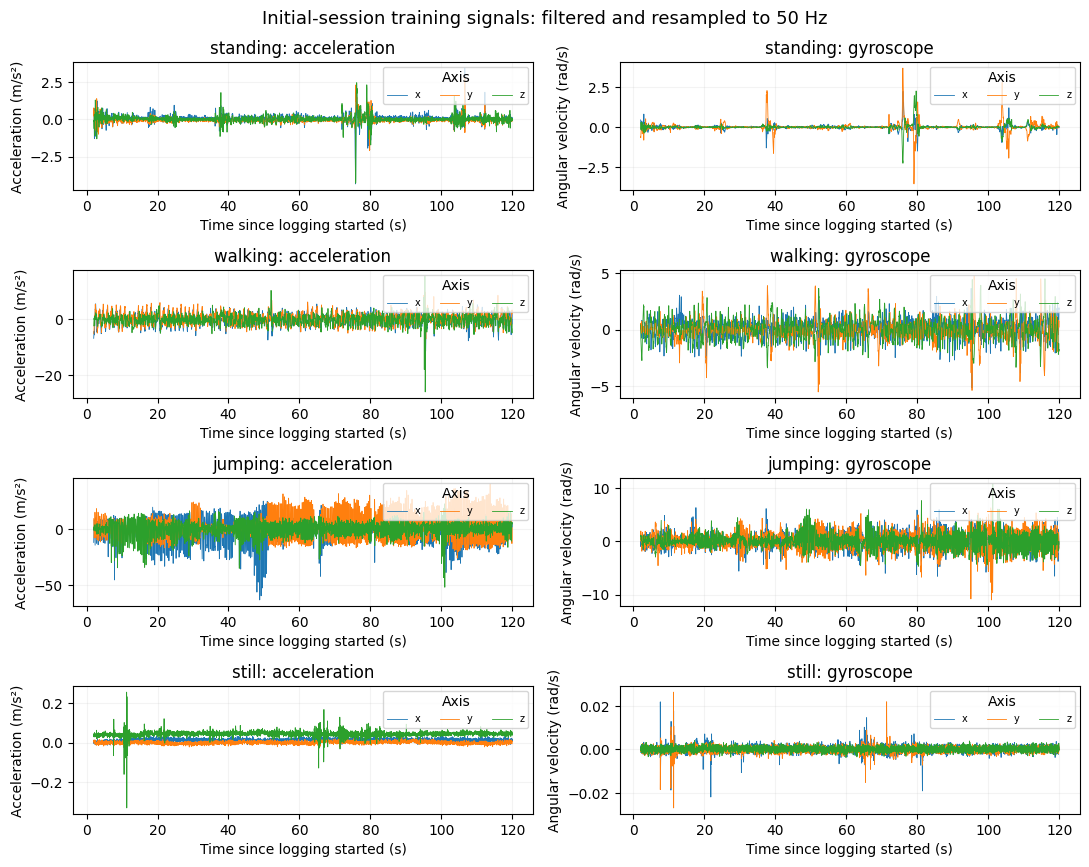

In [4]:
training_examples = [s for s in sequences if s['split'] == 'train']
if training_examples:
    chosen = [next((s for s in training_examples if s['activity'] == state), None) for state in STATES]
    chosen = [s for s in chosen if s is not None]
    fig, axes = plt.subplots(len(chosen), 2, figsize=(11, 2.2 * len(chosen)), squeeze=False)
    for row, s in enumerate(chosen):
        raw = pd.read_csv(ROOT / 'data/processed' / f'{s["recording_id"]}_aligned.csv')
        t = raw.seconds_elapsed
        for axis in ['x', 'y', 'z']:
            axes[row, 0].plot(t, raw[f'acc_{axis}'], label=axis, linewidth=0.6)
            axes[row, 1].plot(t, raw[f'gyro_{axis}'], label=axis, linewidth=0.6)
        axes[row, 0].set(title=f'{s["activity"]}: acceleration', ylabel='Acceleration (m/s²)')
        axes[row, 1].set(title=f'{s["activity"]}: gyroscope', ylabel='Angular velocity (rad/s)')
        for ax in axes[row]:
            ax.set_xlabel('Time since logging started (s)')
            ax.legend(title='Axis', loc='upper right', ncol=3, fontsize=7)
            ax.grid(alpha=0.15)
    fig.suptitle('Initial-session training signals: filtered and resampled to 50 Hz', fontsize=13)
    fig.tight_layout()
    fig.savefig(ROOT / 'results/training_signals.png', dpi=180)
    plt.show()


## 4. Time and frequency features

Each observation contains eight values:

- Acceleration magnitude mean and standard deviation (m/s²).
- Acceleration SMA: mean of |x|+|y|+|z| (m/s²).
- Gyroscope magnitude RMS (rad/s).
- Acceleration and gyroscope dominant magnitude frequencies (Hz), searching 0.5–10 Hz
  after removing the mean and applying a Hann taper.
- Acceleration power fraction in 3–10 Hz relative to 0.5–10 Hz (unitless).
- Gyroscope magnitude AC spectral power, scaled to mean-square power ((rad/s)²).

The 2-second FFT has 0.5 Hz bin spacing. Quiet signals can have noise-driven dominant
frequencies. Magnitudes reduce orientation sensitivity but discard directional detail.
The diagonal-Gaussian model also ignores correlations between these features.


In [5]:
feature_rows = []
for s in sequences:
    for i, vector in enumerate(s['X']):
        feature_rows.append(dict(
            recording_id=s['recording_id'], session_id=s['session_id'], split=s['split'],
            center_s=s['center_s'][i], activity=STATES[s['y'][i]], purity=s['purity'][i],
            stable_core=bool(s['stable'][i]), annotation_quality=s['annotation_quality'],
            **dict(zip(FEATURE_NAMES, vector)),
        ))
if feature_rows:
    feature_frame = pd.DataFrame(feature_rows)
    feature_frame.to_csv(ROOT / 'data/processed/window_features.csv', index=False)
    display(feature_frame.loc[feature_frame.split.eq('train')].head())


,recording_id,session_id,split,center_s,activity,purity,stable_core,annotation_quality,acc_mag_mean,acc_mag_std,acc_sma,gyro_mag_rms,acc_dominant_hz,acc_highband_fraction,gyro_ac_power,gyro_dominant_hz
0,p01_train_jumping_20261028,session_20261028_initial,train,3.0,jumping,1.0,True,participant-labelled single-activity file,10.479822,4.336142,15.878047,1.408132,4.5,0.773010,0.295685,2.5
1,p01_train_jumping_20261028,session_20261028_initial,train,5.0,jumping,1.0,True,participant-labelled single-activity file,9.747187,3.925381,14.838823,1.473114,4.5,0.826120,0.357245,2.0
2,p01_train_jumping_20261028,session_20261028_initial,train,7.0,jumping,1.0,True,participant-labelled single-activity file,11.839688,8.810803,18.317826,2.441658,4.5,0.775102,1.366518,1.5
3,p01_train_jumping_20261028,session_20261028_initial,train,9.0,jumping,1.0,True,participant-labelled single-activity file,12.665509,8.409235,20.684010,1.905928,4.5,0.769094,1.013476,2.5
4,p01_train_jumping_20261028,session_20261028_initial,train,11.0,jumping,1.0,True,participant-labelled single-activity file,9.228295,5.662586,13.725670,1.503506,5.0,0.810302,0.583024,1.0


## 5. HMM components and algorithms

Z = {standing, walking, jumping, still}. X is an eight-dimensional feature vector.
A[i,j] is the next-state probability at one 2-second step; pi is the start distribution.
B consists of four diagonal Gaussian densities, not a discrete emission table.

Estimate emissions directly from labelled isolated training files and guarded cores
of the approximately annotated mixed training run. Estimate A/pi from mixed training
counts with additive smoothing, preserving independent file boundaries. State names
are anchored to training labels, not test predictions.

Viterbi finds the most likely complete path. Forward calculates sequence likelihood.
Baum-Welch is an unlabelled-data alternative and is not run here. Select settings on
validation macro-F1, then assess provisional sensitivity, specificity and accuracy on
the held-out run. The independent-emission baseline checks whether transitions help.
Likelihood alone does not prove classification accuracy. Filtering and Viterbi are offline.

Approximate reference timings limit every subsequent result.


In [6]:
display(Code(inspect.getsource(GaussianHMM), language='python'))


class GaussianHMM:
    """Supervised diagonal-Gaussian HMM with log-space Viterbi and Forward.

    State names are anchored by training labels. Test labels are never used
    for estimation, decoding, or state-name mapping. Baum–Welch is discussed
    in the notebook as an optional unsupervised alternative, not run here.
    """
    def __init__(self, smoothing=1.0, variance_floor=0.1):
        if smoothing <= 0 or variance_floor <= 0:
            raise ValueError("Smoothing and variance_floor must be positive.")
        self.smoothing, self.variance_floor = smoothing, variance_floor

    def fit(self, sequences):
        if not sequences:
            raise ValueError("Training sequences are required.")
        k = len(STATES)
        x = np.concatenate([s["X"] for s in sequences])
        y = np.concatenate([s["y"] for s in sequences])
        pure = np.concatenate([s.get("stable", s["purity"] >= 1 - 1e-6) for s in sequences])
        means, variances = [], []
        for state in range(k):
            selected = x[(y == state) & pure]
            if len(selected) < 2:
                raise ValueError(f"Need at least two pure training windows for {STATES[state]}.")
            means.append(selected.mean(axis=0))
            variances.append(np.maximum(selected.var(axis=0), self.variance_floor))
        self.means_, self.variances_ = np.vstack(means), np.vstack(variances)
        continuous = [s for s in sequences if s["activity"] == "mixed"]
        if not continuous:
            warnings.warn("No mixed training sequence: cross-activity transitions are only smoothing assumptions.")
        transition_sequences = continuous or sequences
        transitions = np.full((k, k), self.smoothing)
        starts = np.full(k, self.smoothing)
        for seq in transition_sequences:
            starts[seq["y"][0]] += 1
            # Never count a transition across independent recording boundaries.
            np.add.at(transitions, (seq["y"][:-1], seq["y"][1:]), 1)
        self.transition_counts_ = transitions - self.smoothing
        self.A_ = transitions / transitions.sum(axis=1, keepdims=True)
        self.pi_ = starts / starts.sum()
        return self

    def log_emissions(self, x):
        x = np.asarray(x)
        if x.ndim != 2 or len(x) == 0 or not np.isfinite(x).all():
            raise ValueError("Observations must be a nonempty finite 2-D array.")
        diff = x[:, None, :] - self.means_[None, :, :]
        return -0.5 * np.sum(np.log(2 * np.pi * self.variances_)[None, :, :]
                             + diff ** 2 / self.variances_[None, :, :], axis=2)

    def decode(self, x):
        """Most likely entire state path; offline, using past and future."""
        b = self.log_emissions(x)
        log_a = np.log(self.A_)
        delta = np.log(self.pi_) + b[0]
        back = np.zeros((len(b), len(STATES)), dtype=int)
        for t in range(1, len(b)):
            candidates = delta[:, None] + log_a
            back[t] = candidates.argmax(axis=0)
            delta = candidates.max(axis=0) + b[t]
        path = np.zeros(len(b), dtype=int)
        path[-1] = delta.argmax()
        for t in range(len(b) - 1, 0, -1):
            path[t - 1] = back[t, path[t]]
        return path

    def score(self, x):
        """Forward algorithm: log P(X), summing over every possible path."""
        b = self.log_emissions(x)
        alpha = np.log(self.pi_) + b[0]
        for emission in b[1:]:
            alpha = emission + logsumexp(alpha[:, None] + np.log(self.A_), axis=0)
        return float(logsumexp(alpha))

    def emission_only(self, x):
        """Diagnostic baseline: classify each window without transitions."""
        return self.log_emissions(x).argmax(axis=1)

## 6. Training-only scaling and validation selection

These are distinct logging runs on the same afternoon, not different people or days.
Use training windows for scaling and fit. Select smoothing/variance floor on validation
macro-F1, with accuracy breaking ties, and freeze the resulting model before scoring
the held-out run. Do not reuse a raw file across splits or tune with test labels.

Mixed training emissions use only windows wholly inside the predefined guarded
interval cores. Approximate full reference sequences supply transition counts.
Validation/test timings were not independently recorded, so selection/evaluation
are provisional. A future independently timed test would strengthen the evidence.


In [7]:
by_split = {name: [s for s in sequences if s['split'] == name]
            for name in ['train', 'validation', 'test']}
def contains_every_state(items):
    return bool(items) and set(np.concatenate([s['y'] for s in items])) == set(range(len(STATES)))

for left, right in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
    shared = {s['session_id'] for s in by_split[left]} & {s['session_id'] for s in by_split[right]}
    if shared:
        raise ValueError(f'Sessions shared across {left} and {right}: {shared}')

training_ready = contains_every_state(by_split['train'])
ready = training_ready and contains_every_state(by_split['validation'])
ready = ready and any(s['activity'] == 'mixed' for s in by_split['train'])
model = None
model_phase = 'not_fitted'
if training_ready:
    scaler_mean, scaler_scale = fit_scaler(by_split['train'])
    scaled = {name: apply_scaler(items, scaler_mean, scaler_scale) for name, items in by_split.items()}
    if ready:
        candidates = []
        for smoothing in [0.1, 1.0]:
            for variance_floor in [0.05, 0.1, 0.2]:
                candidate = GaussianHMM(smoothing, variance_floor).fit(scaled['train'])
                _, _, scores = evaluate(candidate, scaled['validation'])
                candidates.append(dict(smoothing=smoothing, variance_floor=variance_floor, **scores))
        validation_results = pd.DataFrame(candidates).sort_values(
            ['macro_f1', 'accuracy'], ascending=False, kind='stable').reset_index(drop=True)
        display(validation_results)
        validation_results.to_csv(ROOT / 'results/validation_selection.csv', index=False)
        selected = validation_results.iloc[0]
        smoothing, variance_floor = float(selected.smoothing), float(selected.variance_floor)
        model_phase = 'validation_selected'
        model_file = 'fitted_hmm.npz'
        print('Validation selection completed. Freeze these settings before final testing.')
    else:
        smoothing, variance_floor = 1.0, 0.1
        model_phase = 'preliminary_fixed_defaults'
        model_file = 'preliminary_hmm.npz'
        print('Preliminary fit only: fixed defaults, no validation tuning and no unseen accuracy claim.')
        if not any(s['activity'] == 'mixed' for s in scaled['train']):
            print('No observed cross-activity changes: off-diagonal transition probabilities come entirely from smoothing.')
    model = GaussianHMM(smoothing, variance_floor).fit(scaled['train'])
    np.savez(ROOT / 'results' / model_file, A=model.A_, pi=model.pi_,
             means=model.means_, variances=model.variances_,
             scaler_mean=scaler_mean, scaler_scale=scaler_scale,
             feature_names=np.array(FEATURE_NAMES), states=np.array(STATES))
    config = dict(model_phase=model_phase, target_hz=TARGET_HZ, window_s=WINDOW_S,
                  evaluation_status='provisional: approximate reference timings',
                  reference_quality='participant-confirmed orders; signal-assisted boundaries',
                  boundary_guard_s=2, test_order_signal_mismatch=True,
                  smoothing=smoothing, variance_floor=variance_floor,
                  observed_cross_activity_transitions=int(model.transition_counts_.sum() - np.trace(model.transition_counts_)),
                  n_training_recordings=len(scaled['train']),
                  n_training_windows=sum(len(s['y']) for s in scaled['train']),
                  n_validation_recordings=len(scaled['validation']), n_test_recordings=len(scaled['test']),
                  python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__)
    (ROOT / 'results/run_config.json').write_text(json.dumps(config, indent=2))
else:
    print('Fitting needs at least two pure training windows in each of the four activities.')


,smoothing,variance_floor,accuracy,macro_f1,n_windows
0,0.1,0.05,0.571429,0.569444,21
1,0.1,0.10,0.571429,0.569444,21
2,0.1,0.20,0.571429,0.569444,21
3,1.0,0.05,0.571429,0.569444,21
4,1.0,0.10,0.571429,0.569444,21
5,1.0,0.20,0.571429,0.569444,21


Validation selection completed. Freeze these settings before final testing.


## 7. Transition heatmap and observed counts

Rows are current states and columns next states, at a 2-second observation step.
The mixed training run supplies seven cross-activity changes under approximate
annotations. Unobserved changes still get probability from smoothing. Counts reflect
scripted blocks and estimated boundaries, not everyday behaviour frequencies.


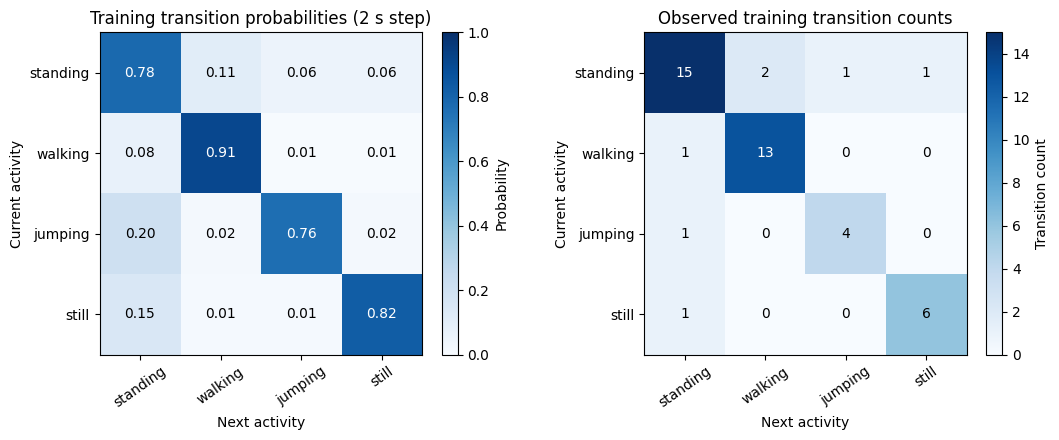

standing    0.785714
walking     0.071429
jumping     0.071429
still       0.071429
Name: Initial-state probability, dtype: float64

In [8]:
if model is not None:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for ax, matrix, title, fmt in [
        (axes[0], model.A_, f'{"Preliminary" if model_phase != "validation_selected" else "Training"} transition probabilities ({WINDOW_S} s step)', '.2f'),
        (axes[1], model.transition_counts_, 'Observed training transition counts', '.0f'),
    ]:
        im = ax.imshow(matrix, cmap='Blues', vmin=0, vmax=1 if fmt == '.2f' else None)
        ax.set_xticks(range(4), STATES, rotation=35)
        ax.set_yticks(range(4), STATES)
        ax.set(xlabel='Next activity', ylabel='Current activity', title=title)
        for i in range(4):
            for j in range(4):
                ax.text(j, i, format(matrix[i,j], fmt), ha='center', va='center',
                        color='white' if matrix[i,j] > matrix.max() * 0.6 else 'black')
        fig.colorbar(im, ax=ax, fraction=0.046, label='Probability' if fmt == '.2f' else 'Transition count')
    fig.tight_layout()
    fig.savefig(ROOT / 'results/transition_matrix.png', dpi=180)
    plt.show()
    pd.DataFrame(model.A_, index=STATES, columns=STATES).to_csv(ROOT / 'results/transition_matrix.csv')
    pd.DataFrame(model.transition_counts_, index=STATES, columns=STATES).to_csv(ROOT / 'results/transition_counts.csv')
    display(pd.Series(model.pi_, index=STATES, name='Initial-state probability'))


## 8. Provisional held-out-run evaluation

The test is a new recording, unused for scaling, fitting or model selection, made a
few minutes after validation by the same person/phone on the same day. This is not
evidence of generalization across days, participants, phones or environments.

Its approximate reference is jumping 2-12 s, walking 12-24 s, still 24-40 s, standing
40-50 s. The quiet/moving signal pattern conflicts with walking/still order. We retain
the participant-confirmed order rather than swap labels after seeing the data.

Sensitivity = TP/(TP+FN), specificity = TN/(TN+FP). The required table counts true
reference-labelled 2-second windows, and repeats one multiclass overall accuracy in
its four rows. Additional one-vs-rest accuracy is clearly labelled. All values are
conditional on uncertain references. The stable-core check excludes a 2 s guard at
estimated interval edges, but cannot resolve a wrong order or inaccurate boundaries.


In [9]:
test_done = False
if model is not None and RUN_FINAL_TEST:
    if model_phase != 'validation_selected':
        raise ValueError('Add separate validation and mixed training data before evaluation.')
    if not contains_every_state(scaled['test']):
        raise ValueError('The test needs all four reference activities.')
    table, confusion, test_scores = evaluate(model, scaled['test'])
    pure_table, _, pure_scores = evaluate(model, scaled['test'], pure_only=True)
    stable_table, _, stable_scores = evaluate(model, scaled['test'], stable_only=True)
    _, _, baseline_scores = evaluate(model, scaled['test'], method='emission_only')
    for frame in [table, pure_table, stable_table]:
        frame['Reference quality'] = 'Participant-confirmed order; approximate signal-assisted timings'
    table.to_csv(ROOT / 'results/test_metrics.csv', index=False)
    pure_table.to_csv(ROOT / 'results/test_metrics_pure_windows.csv', index=False)
    stable_table.to_csv(ROOT / 'results/test_metrics_stable_core.csv', index=False)
    comparison = pd.DataFrame([
        dict(method='Viterbi: all approximate-reference windows', **test_scores),
        dict(method='Viterbi: annotated-pure windows', **pure_scores),
        dict(method='Viterbi: guarded stable cores', **stable_scores),
        dict(method='Emission-only: all approximate-reference windows', **baseline_scores),
    ])
    comparison.to_csv(ROOT / 'results/test_comparison.csv', index=False)
    print('PROVISIONAL: reference timings are estimated and not independently verified.')
    display(table[['Activity','Number of Samples','Sensitivity','Specificity','Overall Accuracy']])
    display(comparison)
    test_done = True
elif not RUN_FINAL_TEST:
    print('Test is disabled until model choices are frozen.')


PROVISIONAL: reference timings are estimated and not independently verified.


,Activity,Number of Samples,Sensitivity,Specificity,Overall Accuracy
0,standing,5,0.800000,0.736842,0.458333
1,walking,6,0.333333,0.722222,0.458333
2,jumping,5,1.000000,1.000000,0.458333
3,still,8,0.000000,0.812500,0.458333


,method,accuracy,macro_f1,n_windows
0,Viterbi: all approximate-reference windows,0.458333,0.469780,24
1,Viterbi: annotated-pure windows,0.458333,0.469780,24
2,Viterbi: guarded stable cores,0.375000,0.430556,16
3,Emission-only: all approximate-reference windows,0.458333,0.466667,24


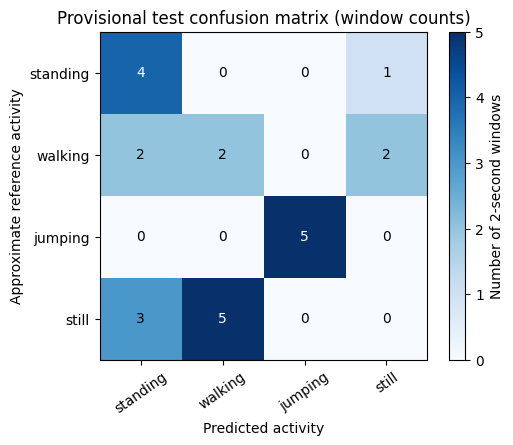

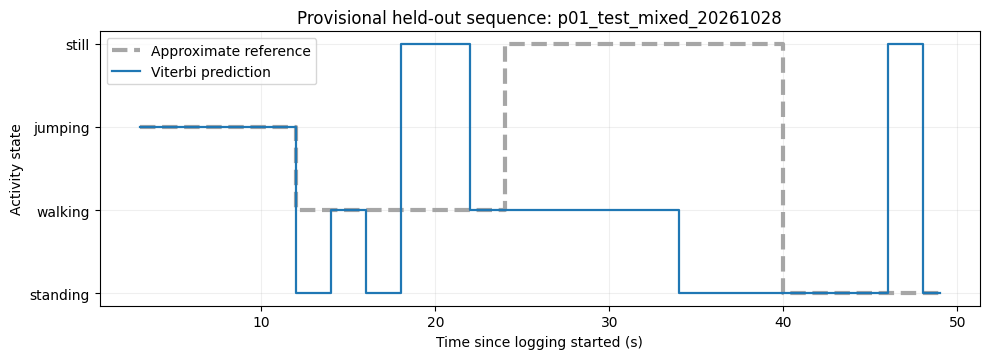

In [10]:
if test_done:
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    im = ax.imshow(confusion, cmap='Blues', vmin=0)
    ax.set_xticks(range(4), STATES, rotation=35)
    ax.set_yticks(range(4), STATES)
    ax.set(xlabel='Predicted activity', ylabel='Approximate reference activity', title='Provisional test confusion matrix (window counts)')
    for i in range(4):
        for j in range(4):
            ax.text(j, i, str(confusion[i,j]), ha='center', va='center',
                    color='white' if confusion[i,j] > confusion.max() * 0.6 else 'black')
    fig.colorbar(im, ax=ax, label='Number of 2-second windows')
    fig.tight_layout(); fig.savefig(ROOT / 'results/confusion_matrix.png', dpi=180)
    plt.show()

    prediction_rows = []
    for s in scaled['test']:
        pred = model.decode(s['X'])
        for t, actual, guessed, purity in zip(s['center_s'], s['y'], pred, s['purity']):
            prediction_rows.append(dict(recording_id=s['recording_id'], center_s=t,
                                        reference_activity=STATES[actual], predicted_activity=STATES[guessed], purity=purity, reference_quality='approximate'))
        if s['activity'] == 'mixed':
            fig, ax = plt.subplots(figsize=(10, 3.7))
            ax.step(s['center_s'], s['y'], where='mid', label='Approximate reference', linestyle='--', linewidth=3, color='0.65')
            ax.step(s['center_s'], pred, where='mid', label='Viterbi prediction', linewidth=1.6)
            ax.set_yticks(range(4), STATES)
            ax.set(xlabel='Time since logging started (s)', ylabel='Activity state',
                   title=f'Provisional held-out sequence: {s["recording_id"]}')
            ax.legend(); ax.grid(alpha=0.2); fig.tight_layout()
            fig.savefig(ROOT / 'results' / f'decoded_{s["recording_id"]}.png', dpi=180)
            plt.show()
    pd.DataFrame(prediction_rows).to_csv(ROOT / 'results/test_predictions.csv', index=False)


## 9. Interpretation and remaining work

Report actual provisional results, including low scores. Do not rename walking/still
references to increase accuracy. The four new single-activity files provide a clearer v2 state-recognition test;
they do not test recognition of changes within a continuous recording. Stable-core scores test boundary
sensitivity; they do not verify the labels.

Discuss scripted transitions, small test counts, same-person/same-day split, uncertain
timing, possible placement/pace changes, noise and diagonal-Gaussian assumptions.
The phone-on-surface state does not reveal the owner's movement away from the phone.

The replacement videos exceed five seconds in total; sampled still frames crop part
of the person at the left edge. The public video links, author details and GitHub repository link are included in
the updated report. See rubric_status.md for remaining rubric requirements.

References: [Sensor Logger help](https://www.tszheichoi.com/sensorloggerhelp),
[units](https://github.com/tszheichoi/awesome-sensor-logger/blob/main/UNITS.md),
[HMM tutorial](https://hmmlearn.readthedocs.io/en/stable/tutorial.html).


## 10. V2 improvement using development data only

The eight fixed comparisons vary all-eight versus compact-four features, raw versus
log1p scaling, and window versus recording-balanced emissions. Smoothing/floor stay
fixed. Selection uses validation macro-F1, accuracy, fewer features and standard fit
as tie-breakers. Approximate validation labels and a single 21-window run remain
limitations. Historical test performance is not used to choose a candidate, and the
v2 comparison never reads a test sensor file. The frozen v2 model is subsequently evaluated on separate unseen files.

The selected four features retain both time and frequency domains. The following cell displays the saved comparison and selected model metadata.
Run improve_model.py explicitly only if intentionally starting a new development cycle;
rerunning this notebook does not replace the frozen model used for the fresh test.


,candidate,features,transform,weighting,n_features,accuracy,macro_f1,n_windows,stable_core_accuracy
0,compact4_log1p_window,compact4,log1p,window,4,0.904762,0.904040,21,1.000000
1,compact4_raw_recording,compact4,raw,recording,4,0.904762,0.904040,21,1.000000
2,compact4_log1p_recording,compact4,log1p,recording,4,0.904762,0.904040,21,1.000000
3,all8_log1p_window,all8,log1p,window,8,0.857143,0.857828,21,1.000000
4,all8_log1p_recording,all8,log1p,recording,8,0.857143,0.857828,21,1.000000
5,compact4_raw_window,compact4,raw,window,4,0.809524,0.786797,21,0.846154
6,all8_raw_window,all8,raw,window,8,0.571429,0.569444,21,0.615385
7,all8_raw_recording,all8,raw,recording,8,0.571429,0.569444,21,0.615385


Selected before fresh test: compact4_log1p_window
Validation: 90.48%


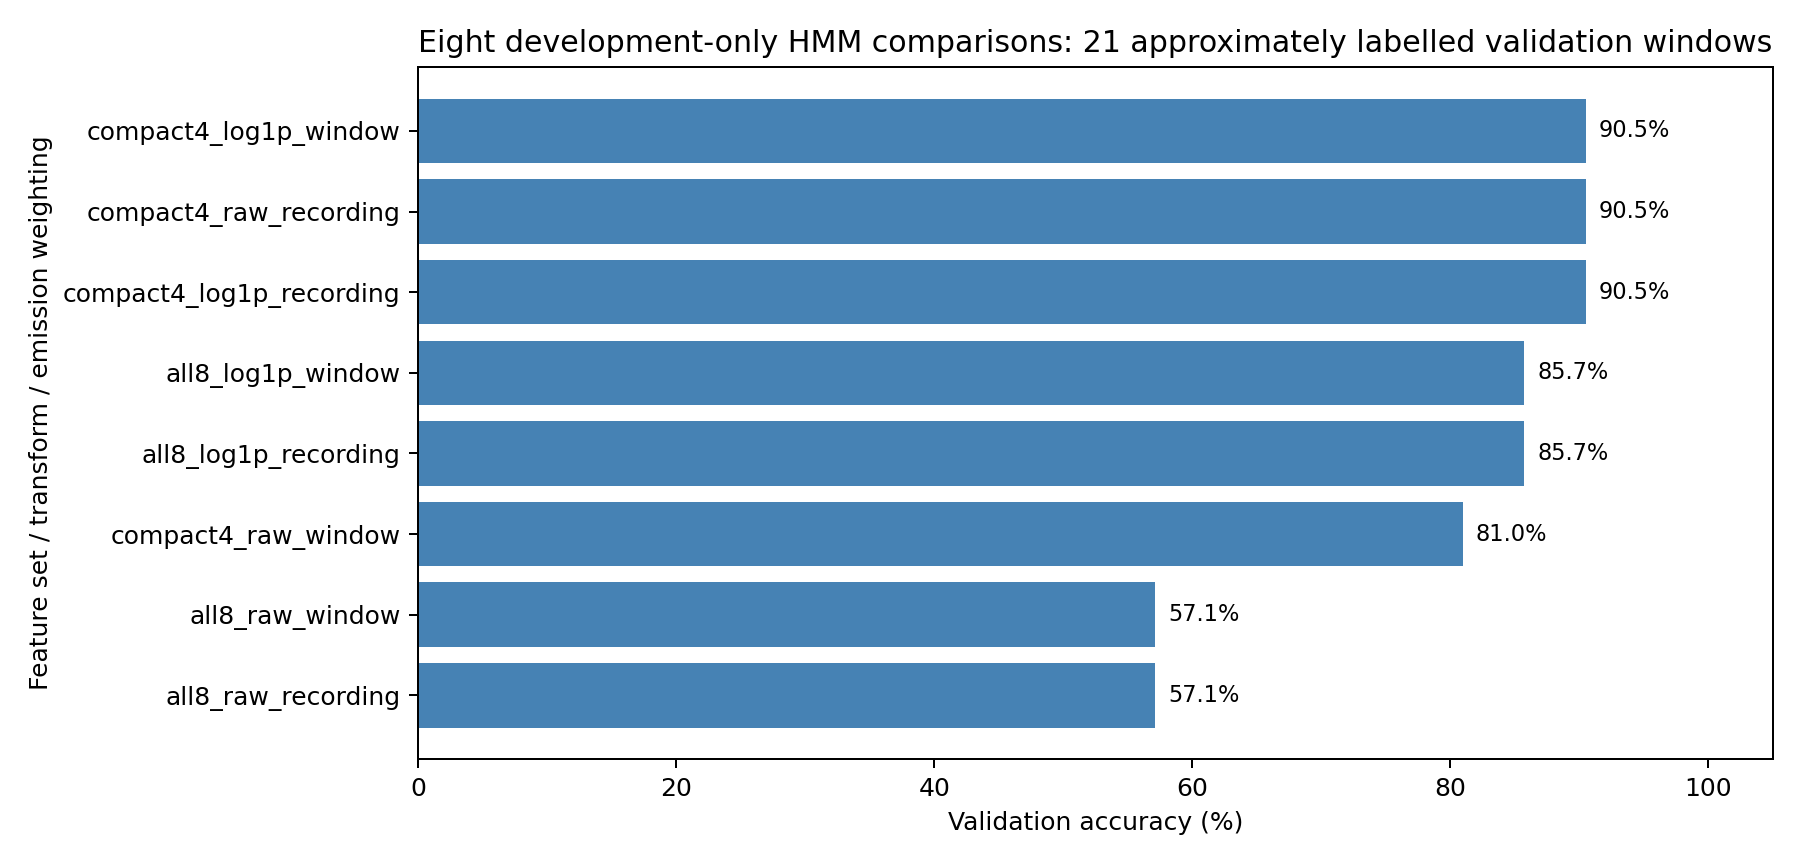

In [11]:
from IPython.display import Image as DisplayImage
v2_comparison = pd.read_csv(ROOT / 'results/improvement_v2/validation_comparison.csv')
v2_info = json.loads((ROOT / 'results/improvement_v2/selection.json').read_text())
display(v2_comparison)
print('Selected before fresh test:', v2_info['selected_candidate'])
print('Validation:', f"{v2_info['validation_accuracy']:.2%}")
display(DisplayImage(filename=str(ROOT / 'results/improvement_v2/validation_comparison.png')))


## 11. Fresh unseen v2 test: four separately labelled recordings

These four Sensor Logger ZIPs were collected later the same day, after choosing and
saving the v2 model. Each file contains just one participant-labelled activity; no
change-time estimates are needed. The fixed preprocessing rule discards the first
2 seconds and any incomplete final 2-second window. The saved v2 model is loaded
without fitting or selecting settings. Each file is decoded separately.

The results measure recognition of steady states for this participant and iPhone.
They do not measure transitions in a continuous mixed run, and the 30 adjacent
windows are correlated. The old 45.83% mixed-run result is historical v1 evidence.


Frozen v2 fresh test: 27/30 = 90.00% | macro-F1: 0.888


,Activity,Number of Samples,Sensitivity,Specificity,Overall Accuracy
0,standing,7,0.571429,1.000000,0.9
1,walking,8,1.000000,1.000000,0.9
2,jumping,8,1.000000,1.000000,0.9
3,still,7,1.000000,0.869565,0.9


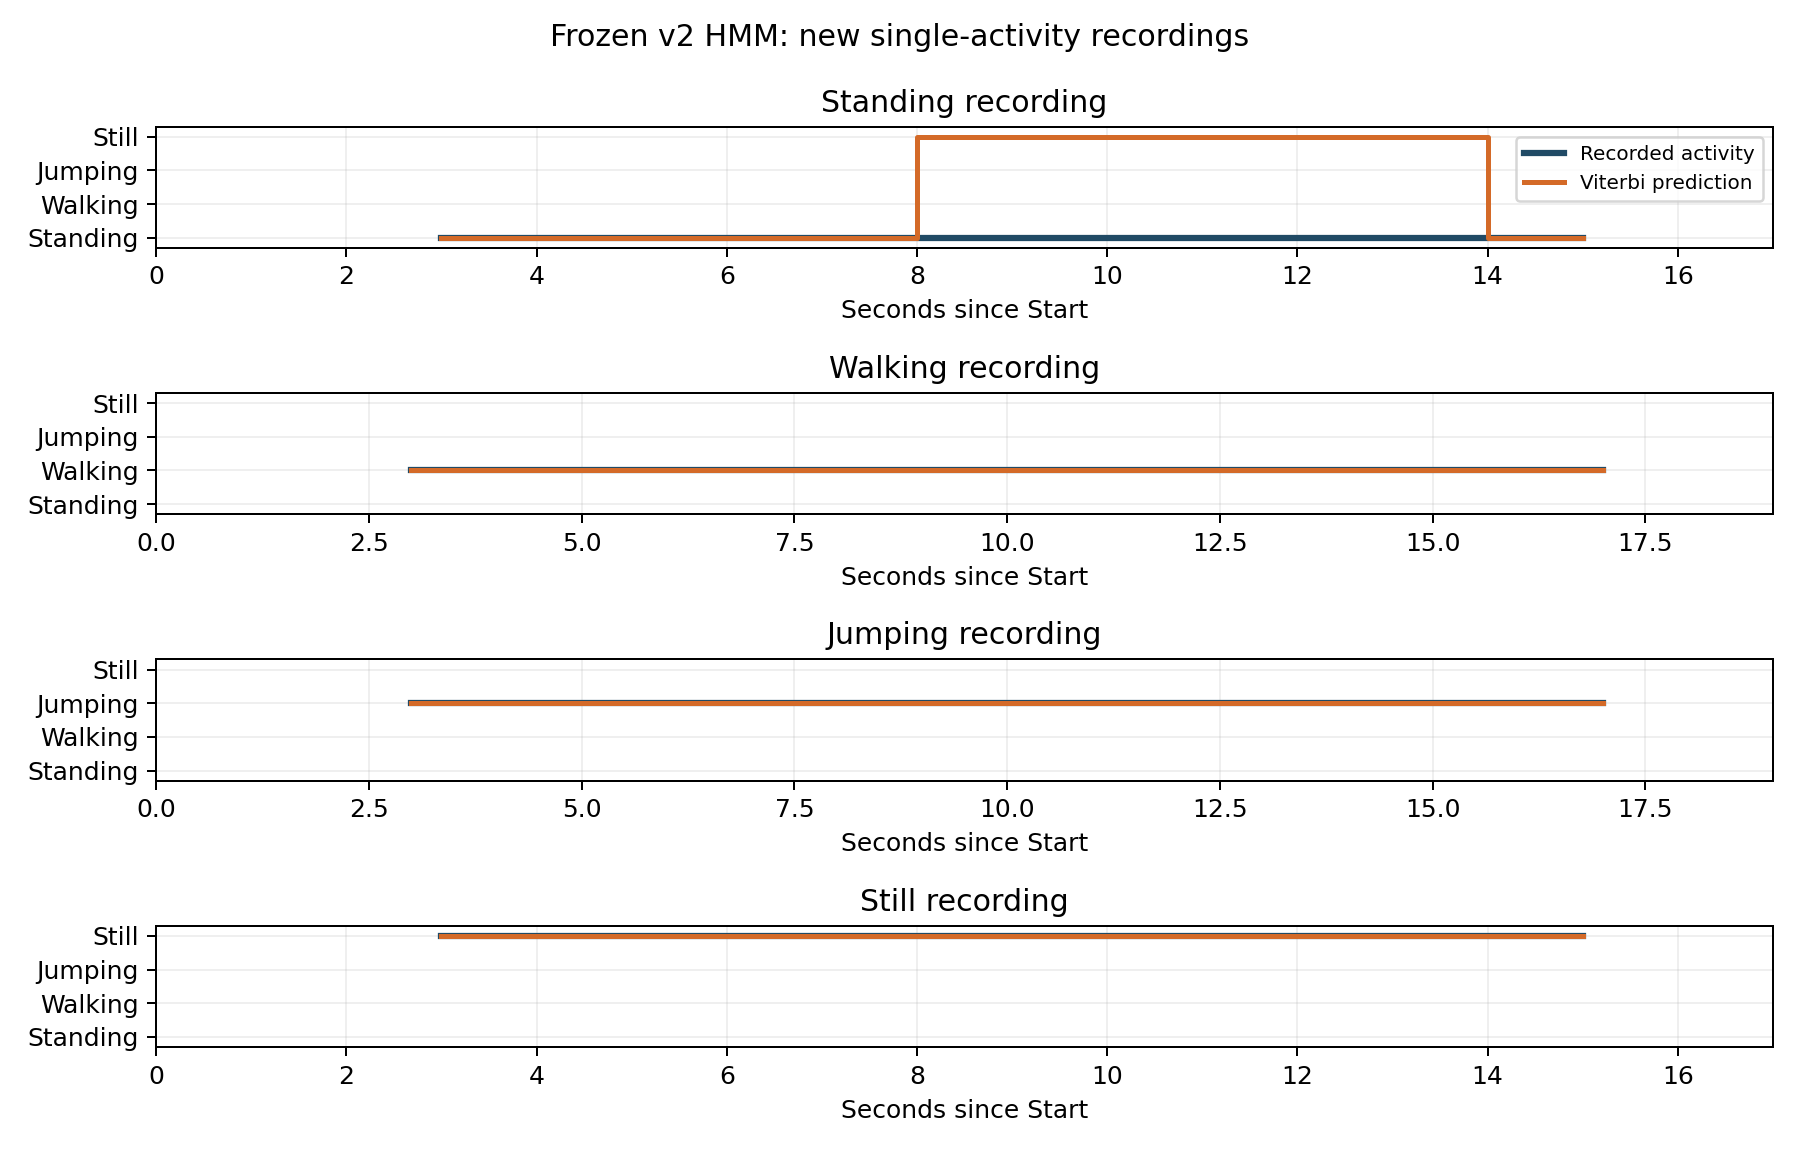

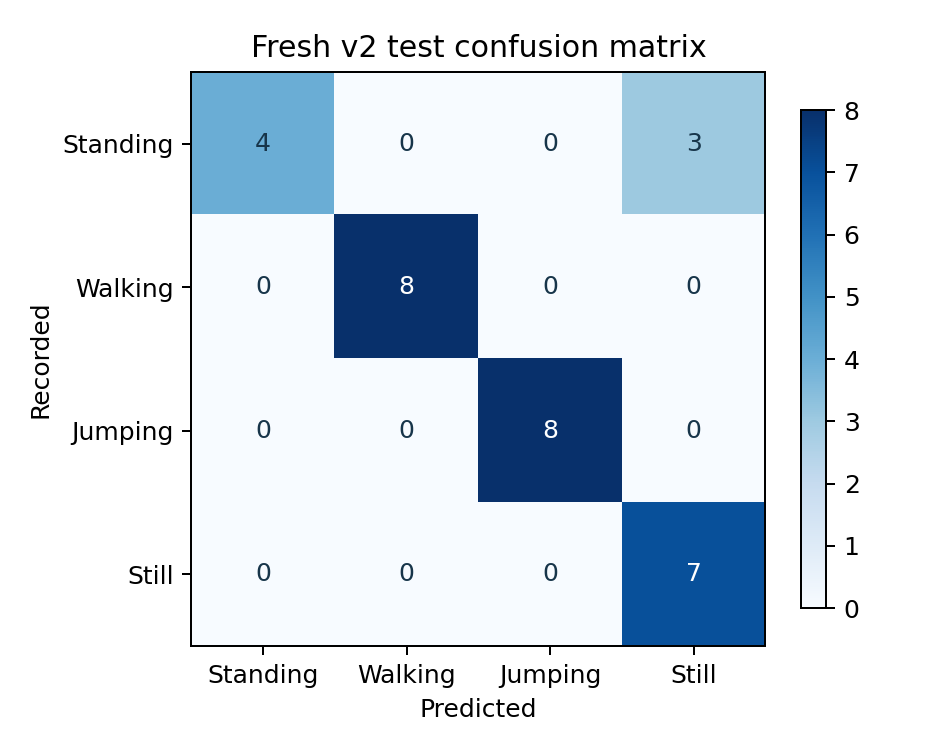

In [12]:
from evaluate_fresh_v2 import run_evaluation
fresh_summary, fresh_table, fresh_confusion = run_evaluation()
print('Frozen v2 fresh test:', f"{fresh_summary['correct_windows']}/{fresh_summary['n_windows']}",
      f"= {fresh_summary['accuracy']:.2%}", '| macro-F1:', f"{fresh_summary['macro_f1']:.3f}")
display(fresh_table[['Activity', 'Number of Samples', 'Sensitivity', 'Specificity', 'Overall Accuracy']])
display(DisplayImage(filename=str(ROOT / 'results/fresh_test_v2/decoded_sequences.png')))
display(DisplayImage(filename=str(ROOT / 'results/fresh_test_v2/confusion_matrix.png')))
